# 6. Машин суралцал (бонус)

`python -m src.models` бүх загварыг сургаж, `reports/metrics.json`-д бичдэг.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
P, R, F = ROOT / "data" / "processed", ROOT / "reports", ROOT / "figures"
def show(name):
    display(Image(filename=str(F / f"{name}.png"), width=760))

In [2]:
m = json.loads((R / "metrics.json").read_text(encoding="utf-8"))
print("K-Means: k =", m["kmeans"]["k"], "silhouette =", round(m["kmeans"]["silhouette"], 3), "bootstrap ARI =", round(m["kmeans"]["bootstrap_ari"], 3))

K-Means: k = 3 silhouette = 0.215 bootstrap ARI = 0.779


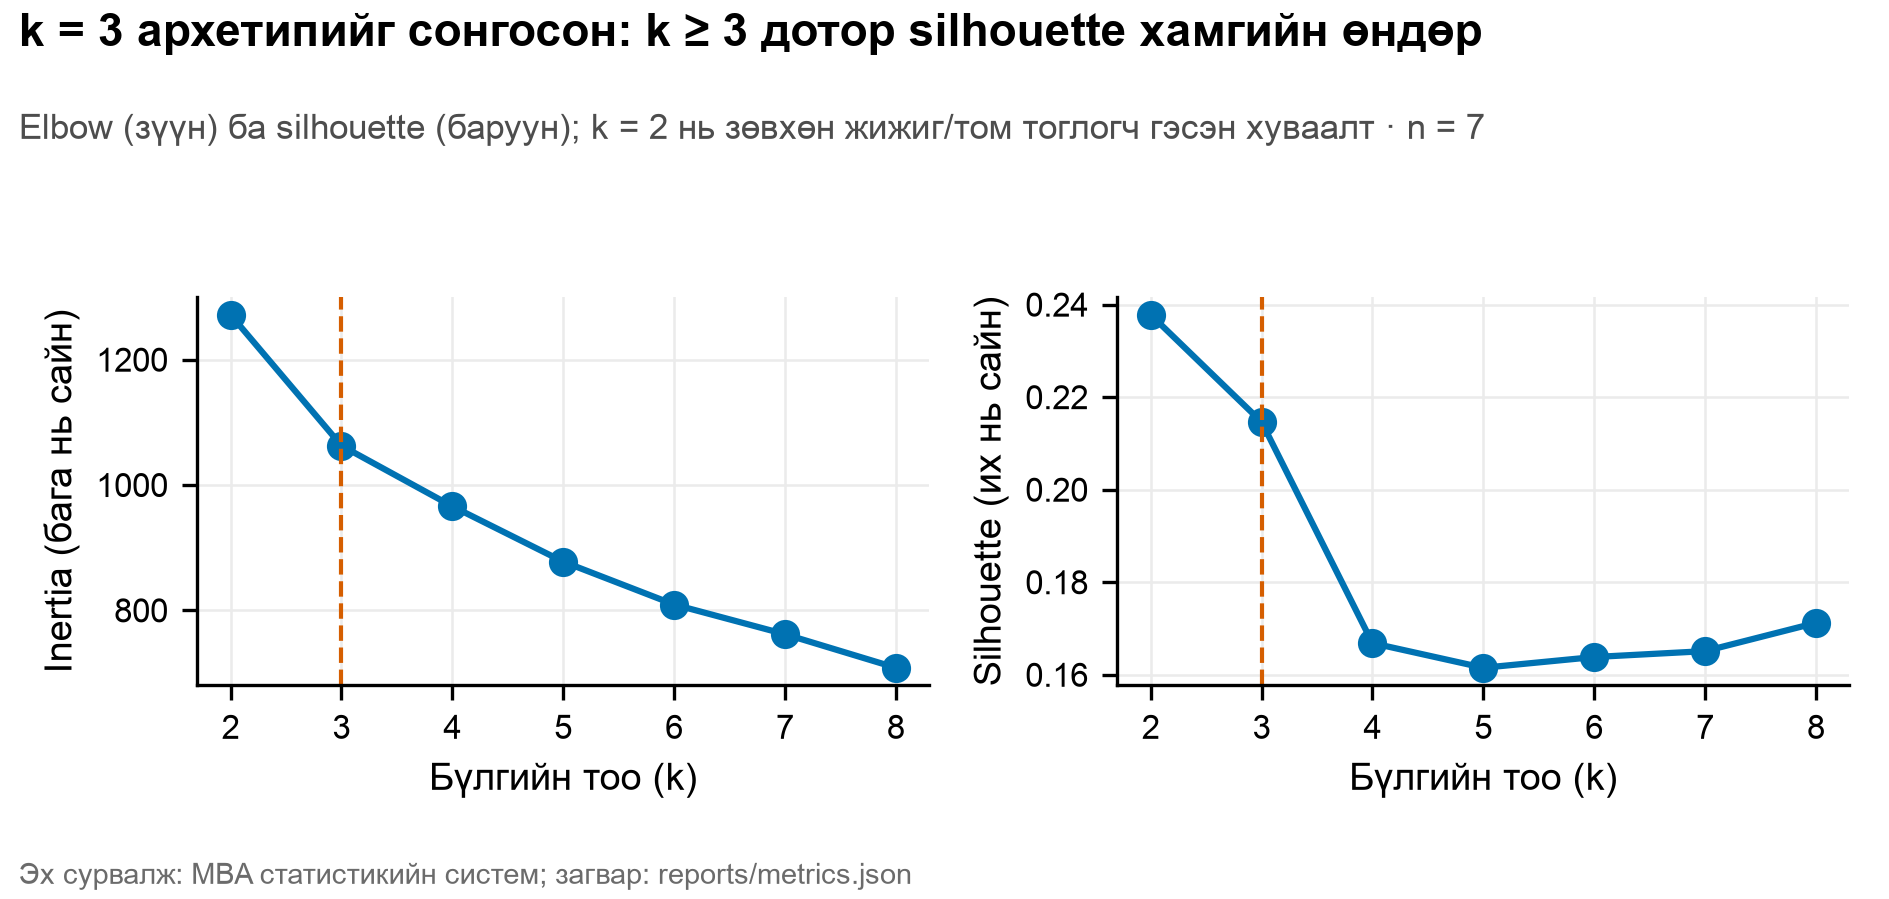

In [3]:
show("F14a_elbow_silhouette")

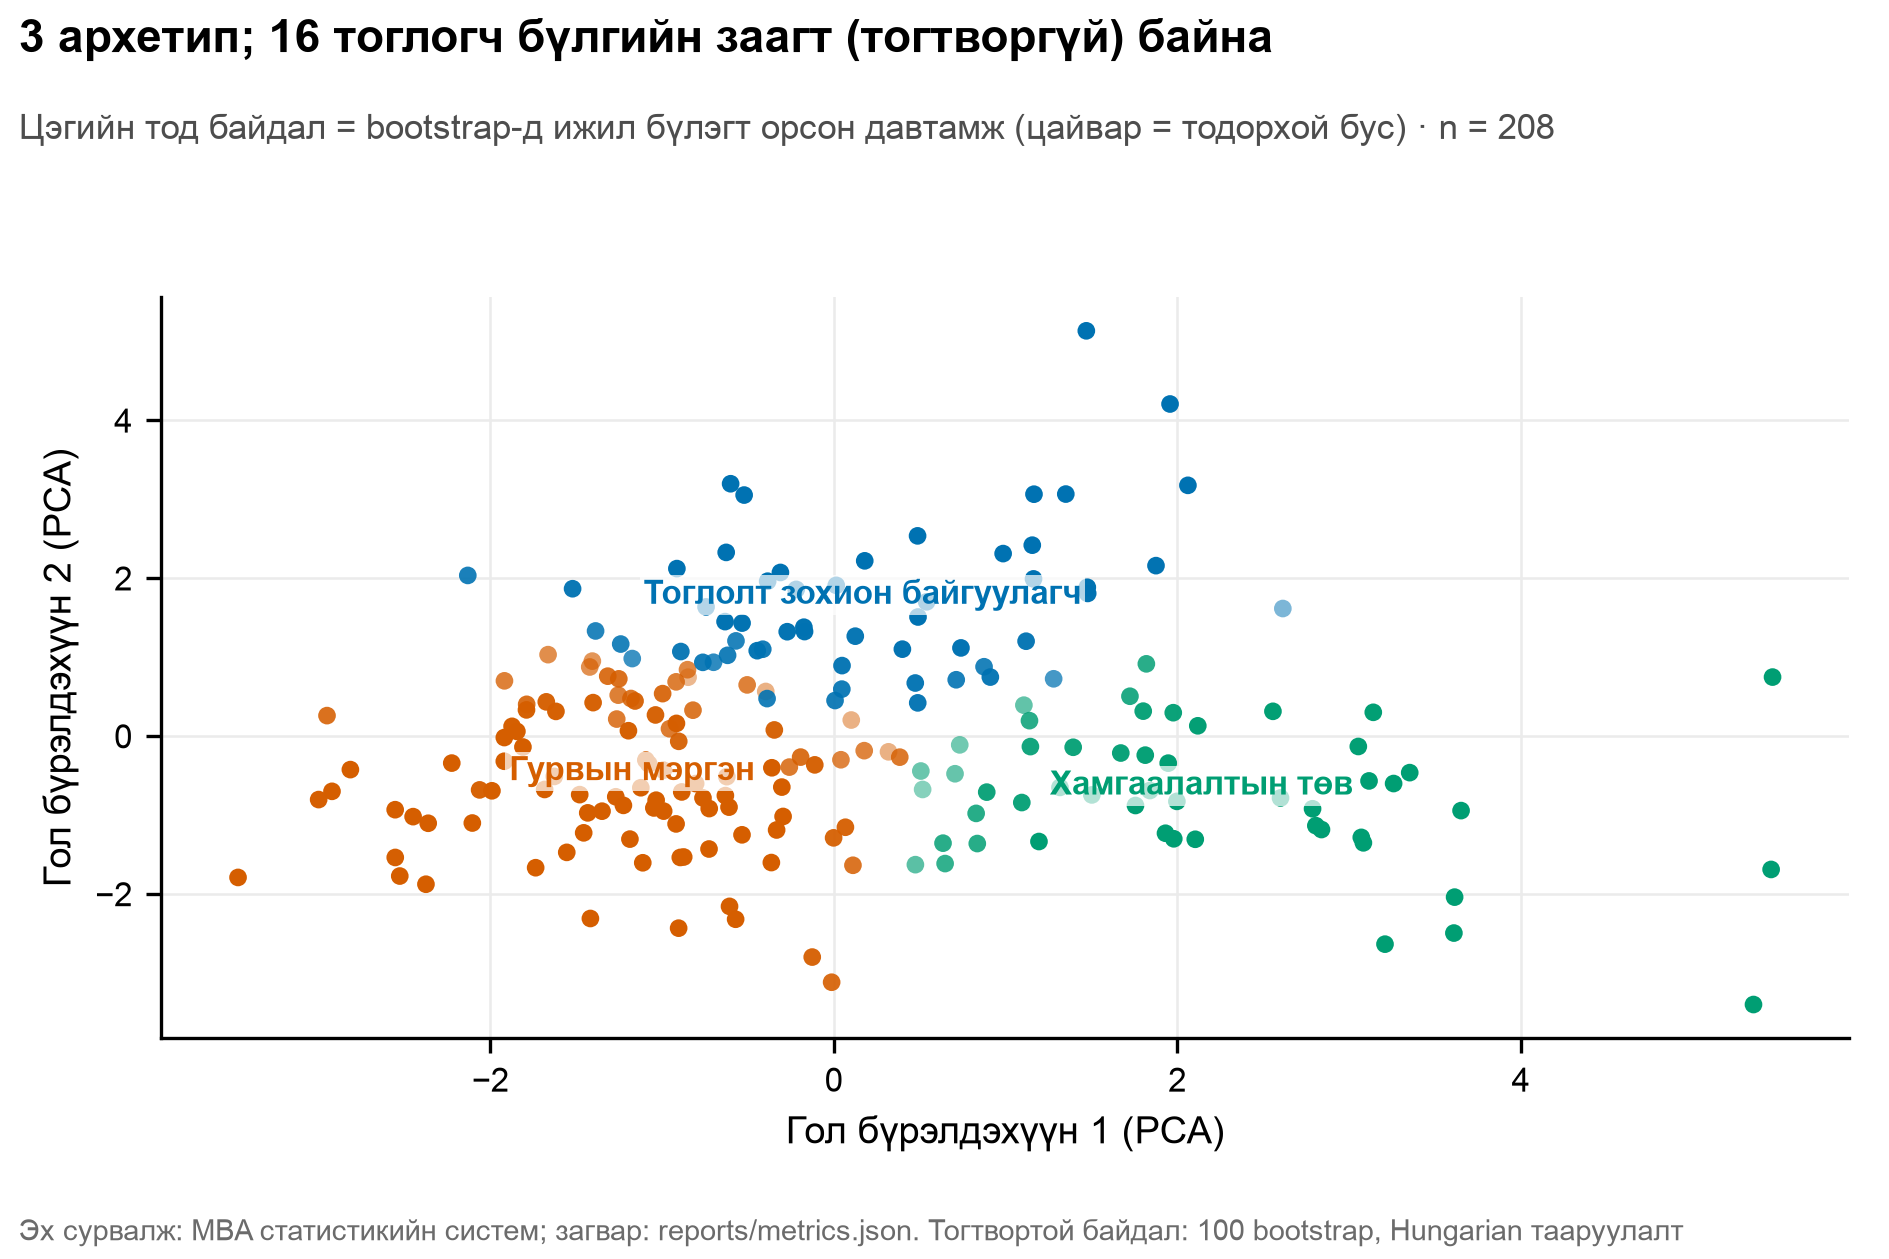

In [4]:
show("F14b_pca_clusters")

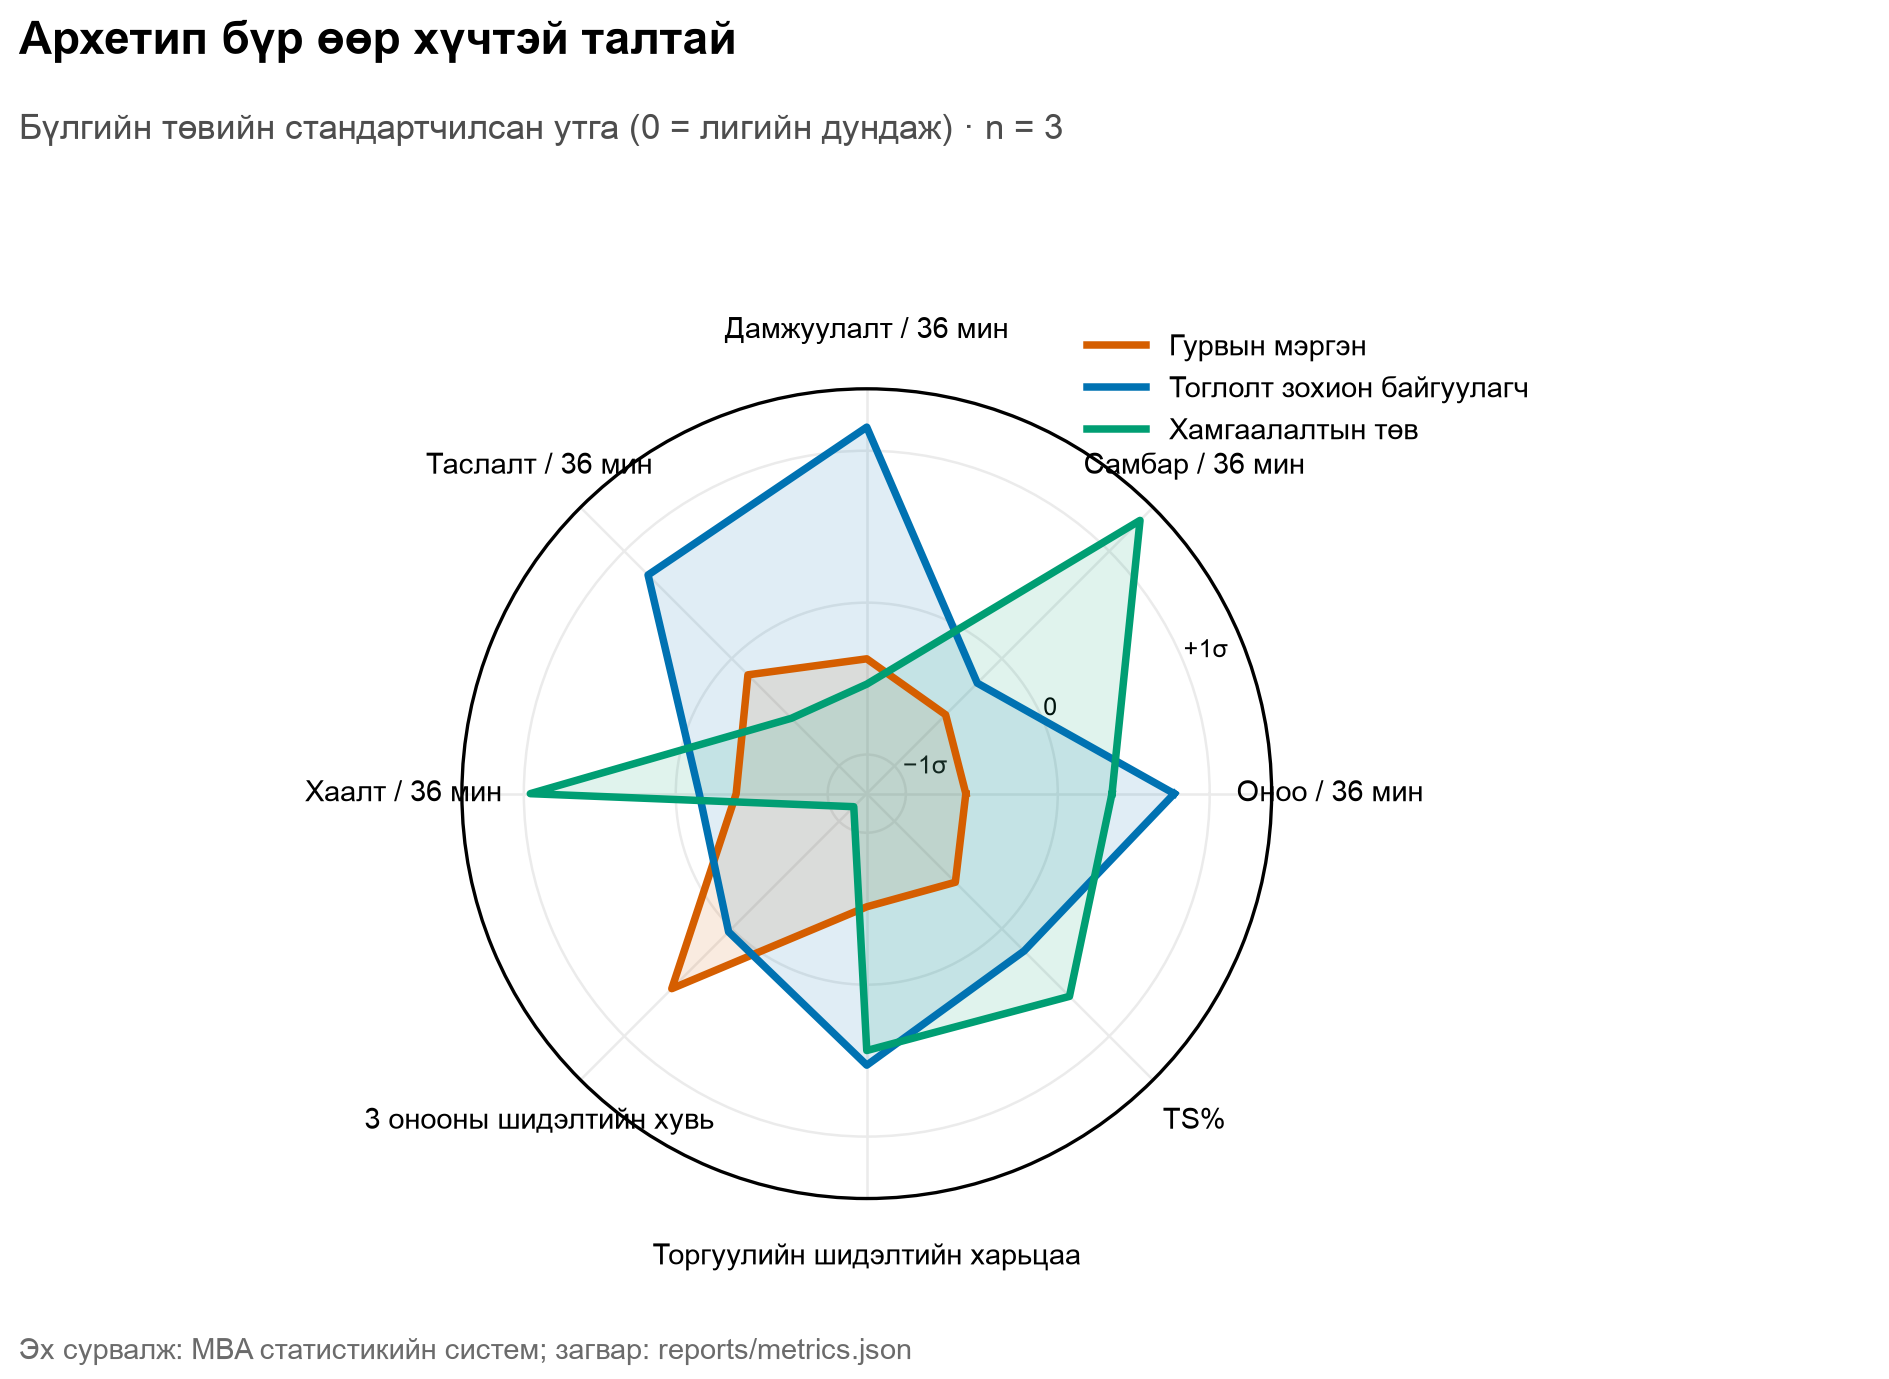

In [5]:
show("F14c_radar")

In [6]:
display(pd.read_csv(R / "cluster_composition.csv")); pd.read_csv(R / "cluster_centroids.csv").round(3)

,cluster_name,n,pct_import,PG,SG,SF,PF,C
0,Гурвын мэргэн,101,5.940594,20,33,21,18,9
1,Тоглолт зохион байгуулагч,56,50.000000,31,12,9,2,2
2,Хамгаалалтын төв,51,52.941176,4,2,5,9,31


,cluster_name,pts36,reb36,ast36,stl36,blk36,tpa_rate,ftr,ts_pct
0,Хамгаалалтын төв,15.800,9.804,2.067,1.220,1.237,0.146,0.370,0.577
1,Гурвын мэргэн,10.529,4.729,2.359,1.525,0.306,0.517,0.227,0.499
2,Тоглолт зохион байгуулагч,18.045,5.556,5.032,2.227,0.473,0.401,0.385,0.546


## Ялалтын таамаглал (walk-forward CV)

In [7]:
pd.DataFrame(m["win_cv"]).T.round(3)

,accuracy_mean,accuracy_std,auc_mean,auc_std,brier_mean,brier_std
baseline_elo,0.603,0.059,0.603,0.063,0.397,0.059
baseline_winpct,0.570,0.019,0.597,0.015,0.391,0.021
logreg,0.592,0.091,0.655,0.116,0.233,0.034
rf,0.547,0.081,0.591,0.084,0.255,0.028


In [8]:
pd.DataFrame({k: {kk: f"{vv['est']:.3f} [{vv['lo']:.3f}, {vv['hi']:.3f}]" for kk, vv in v.items()} for k, v in m["win_bootstrap"].items()}).T

,accuracy,auc,brier
baseline_elo,"0.601 [0.530, 0.667]","0.601 [0.531, 0.668]","0.399 [0.333, 0.470]"
baseline_winpct,"0.568 [0.497, 0.634]","0.594 [0.522, 0.666]","0.391 [0.326, 0.454]"
logreg,"0.585 [0.519, 0.656]","0.638 [0.563, 0.716]","0.235 [0.213, 0.258]"
rf,"0.546 [0.481, 0.617]","0.583 [0.503, 0.661]","0.257 [0.234, 0.283]"


In [9]:
pd.read_csv(R / "season_holdout.csv").round(3)

,model,n_train,n_test,accuracy,auc,brier
0,logreg,156,64,0.641,0.659,0.224
1,rf,156,64,0.594,0.604,0.244
2,baseline_elo,156,64,0.641,0.641,0.359
3,baseline_winpct,156,64,0.531,0.584,0.379


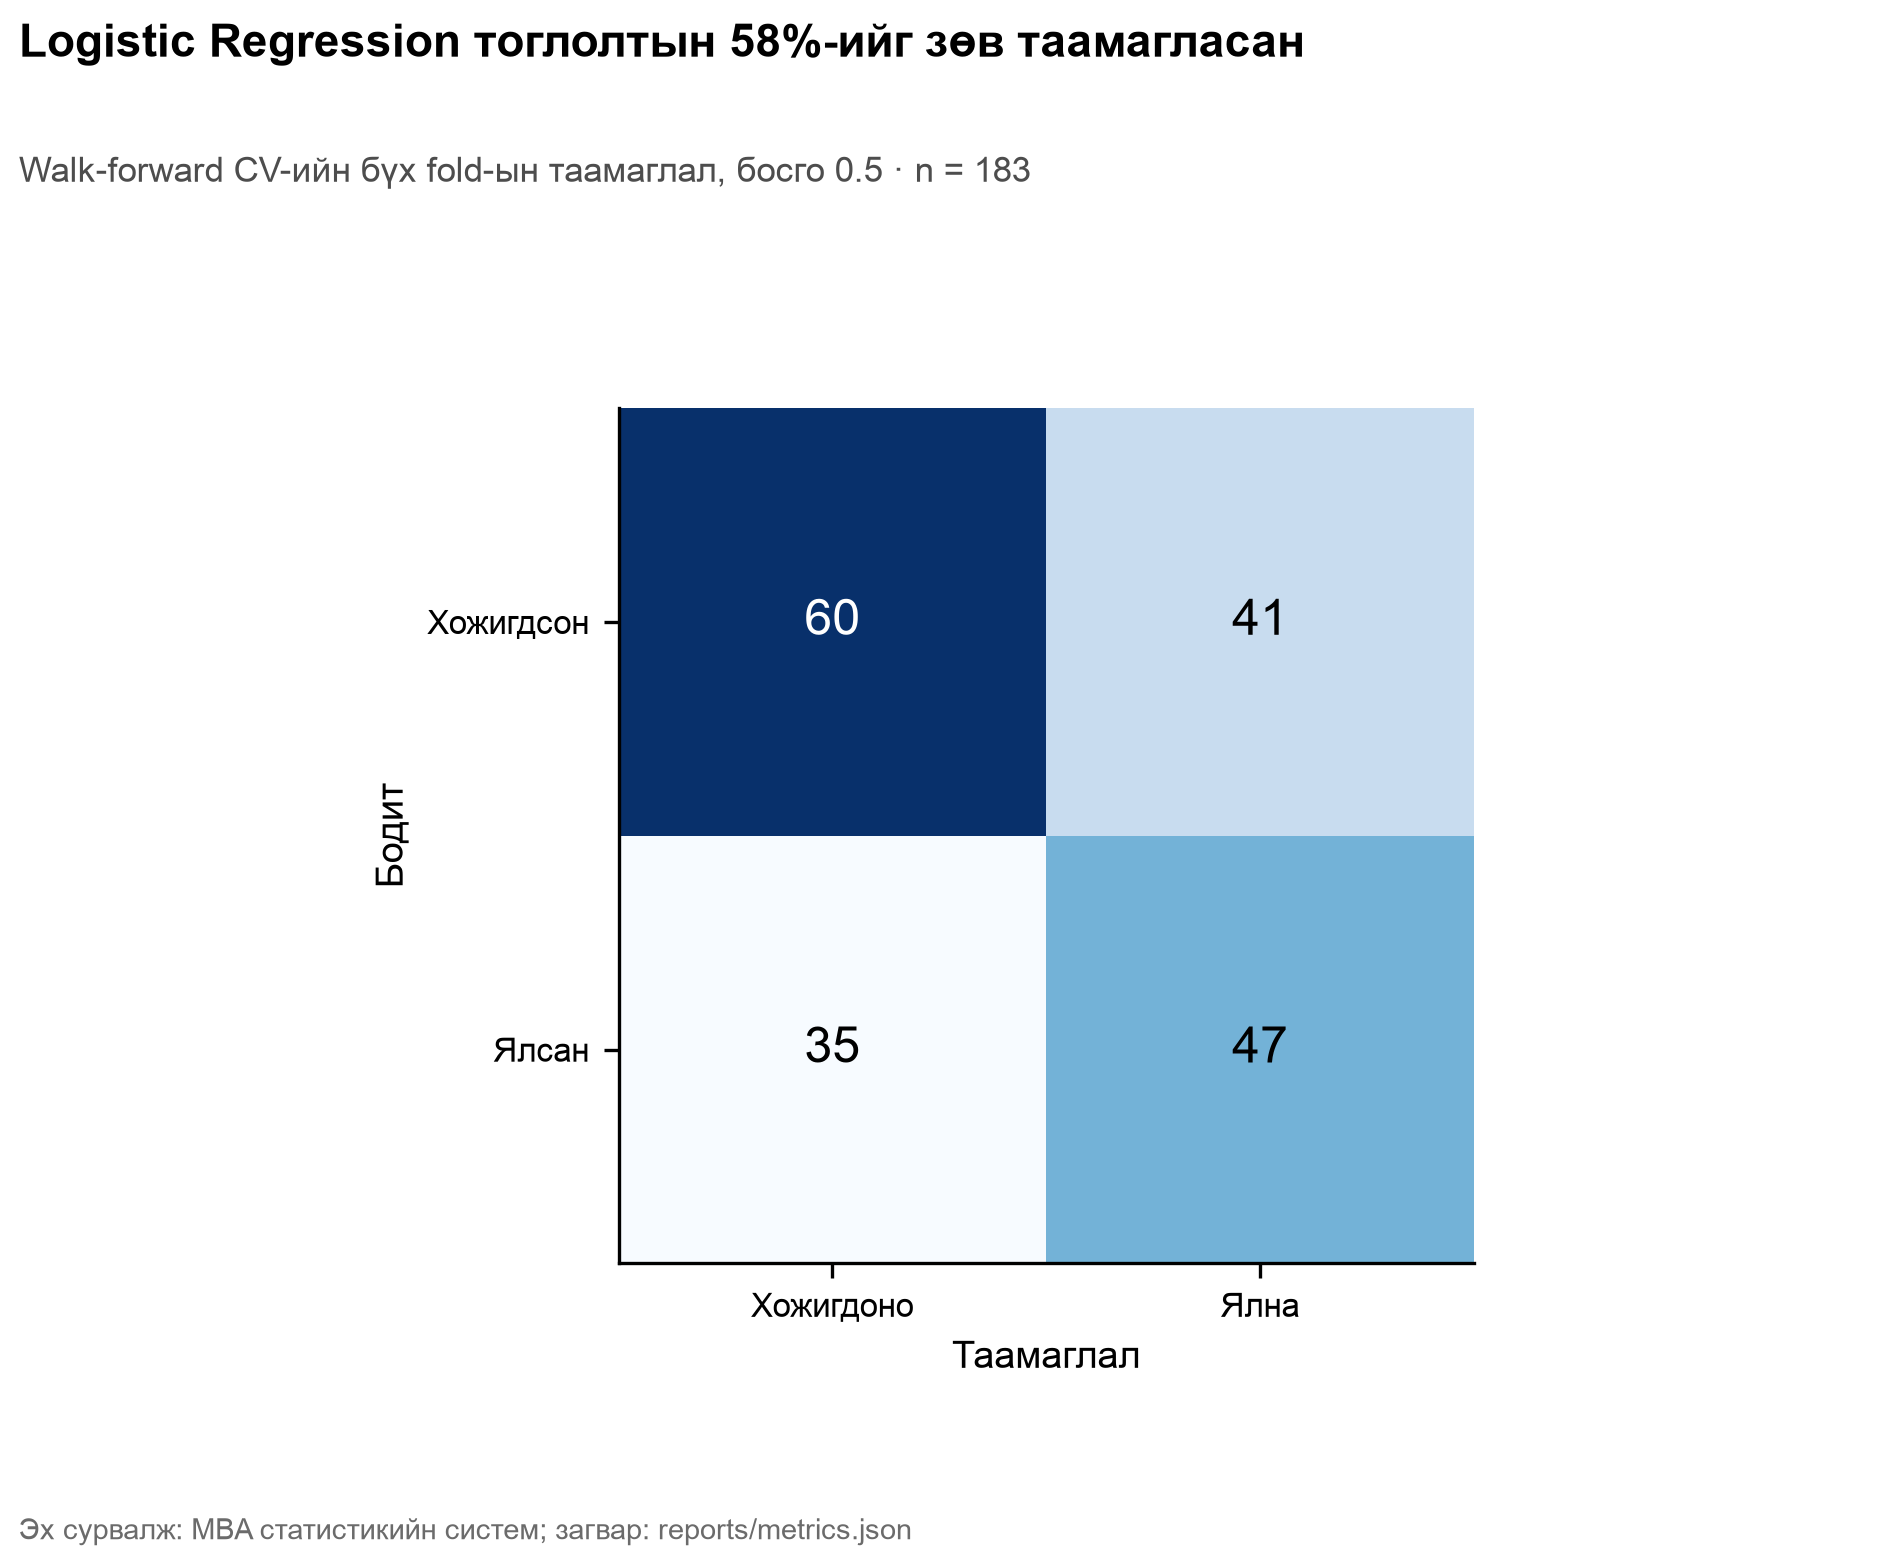

In [10]:
show("F14d_confusion")

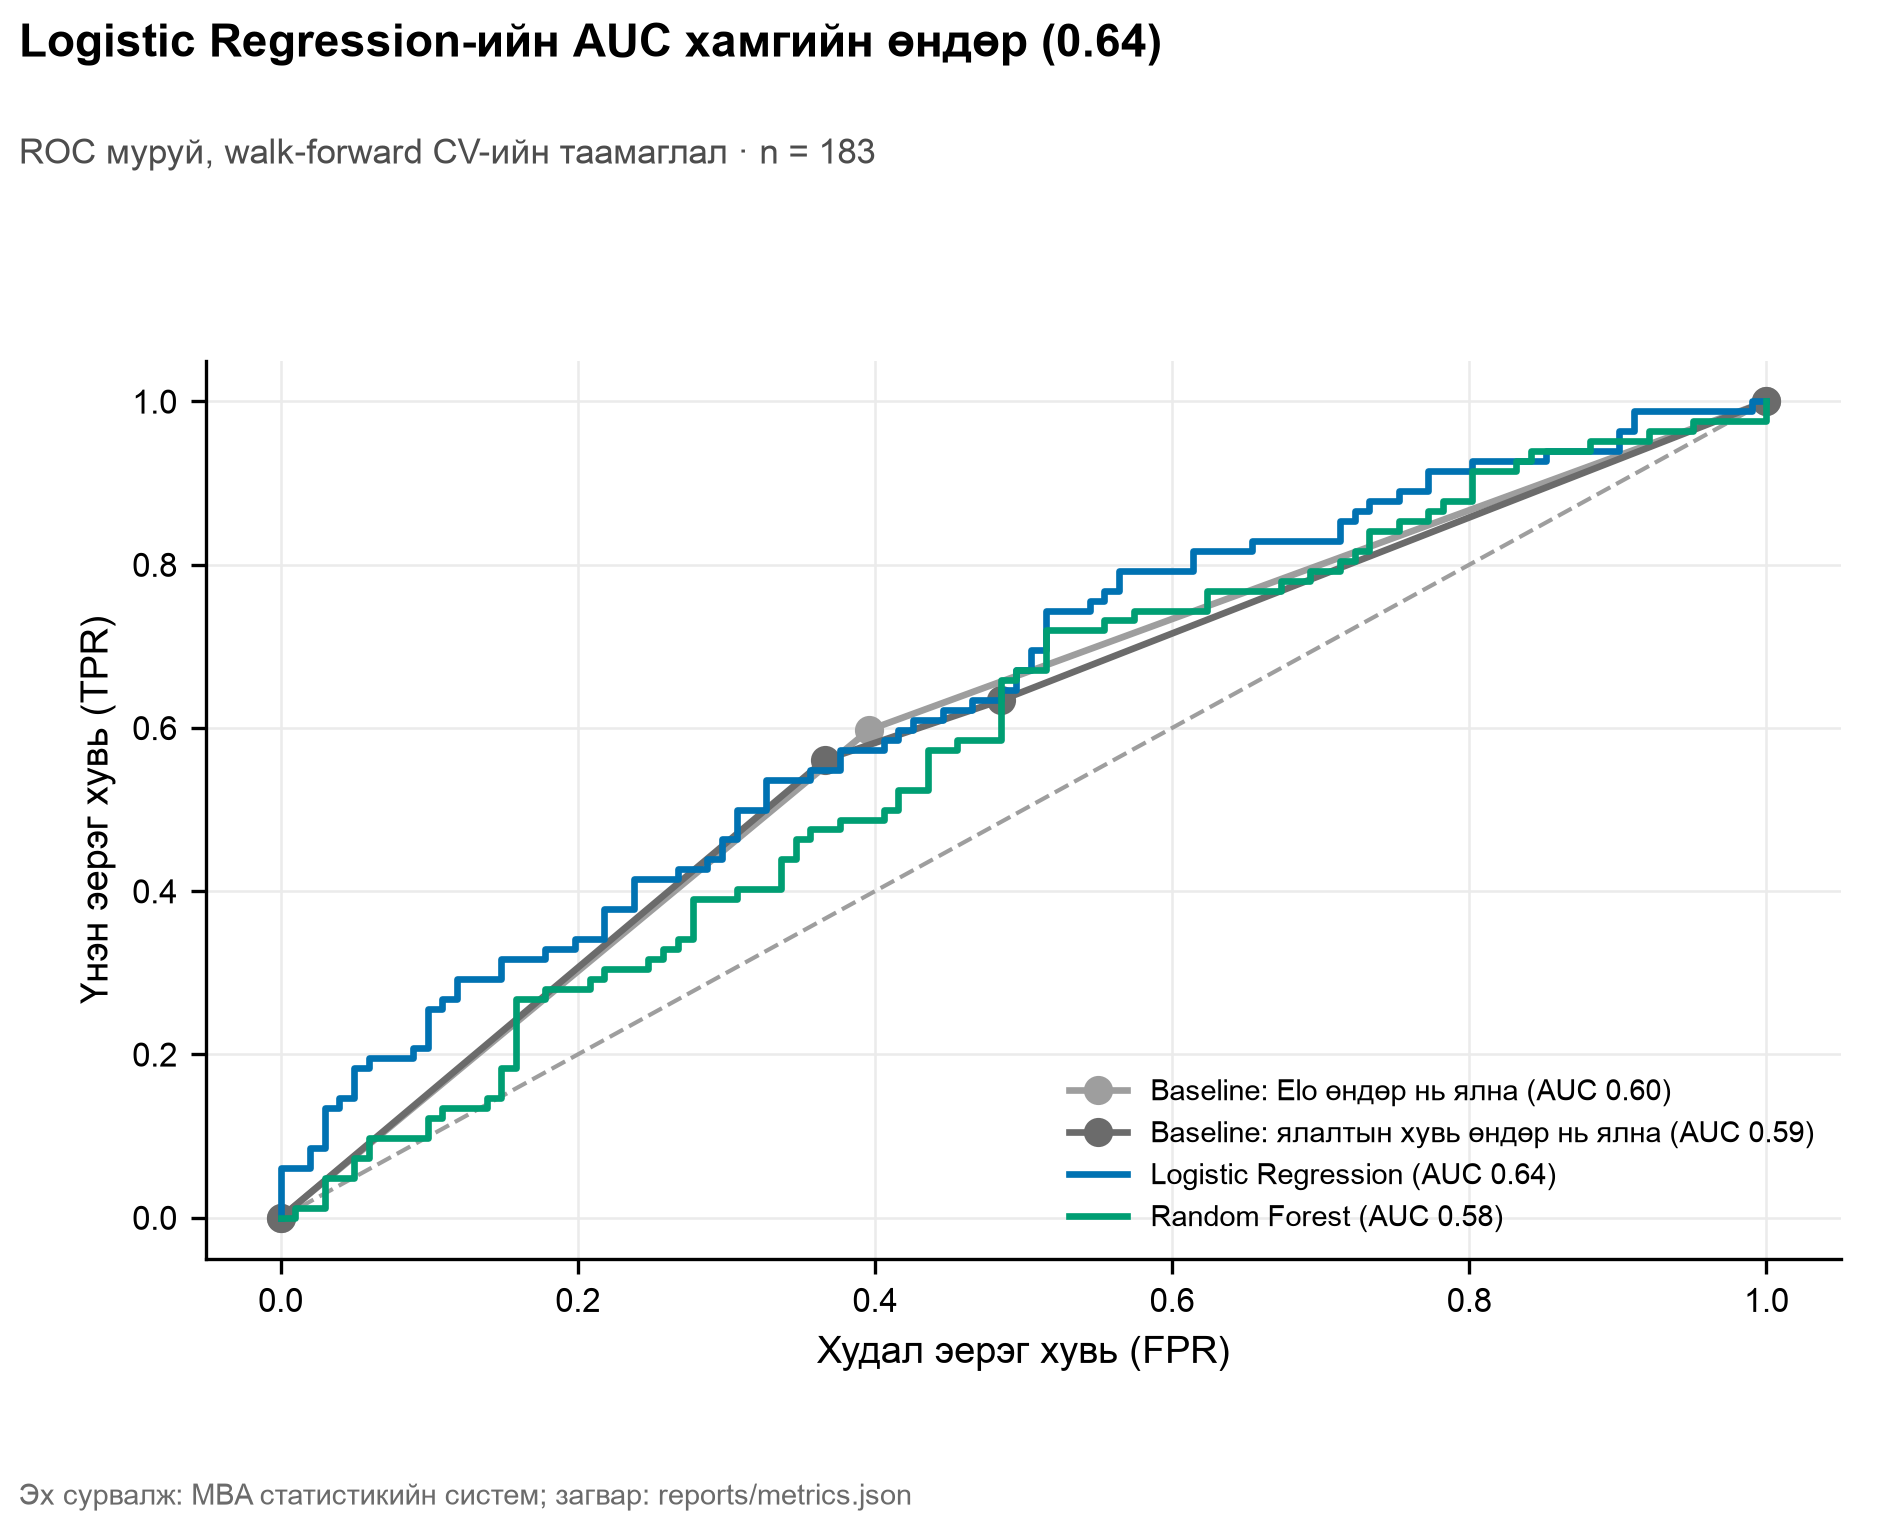

In [11]:
show("F14e_roc")

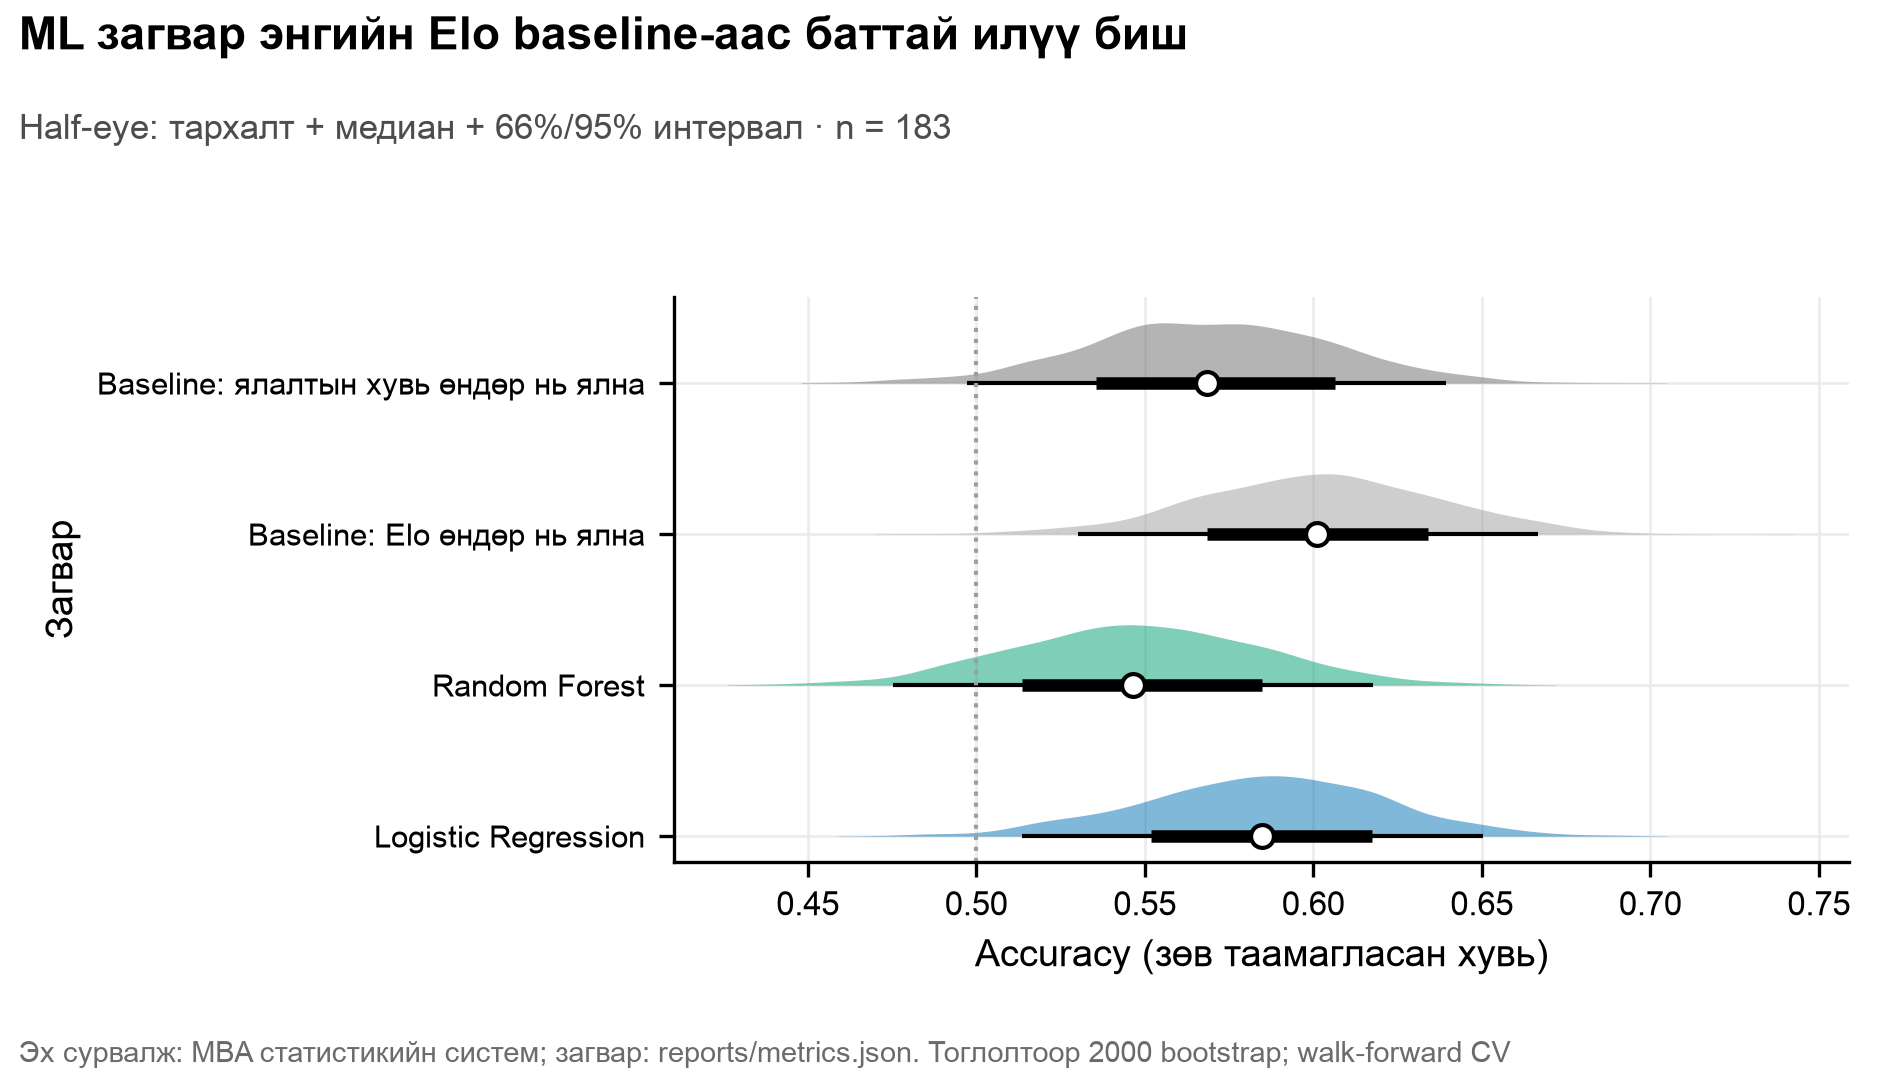

In [12]:
show("U06a_model_accuracy")

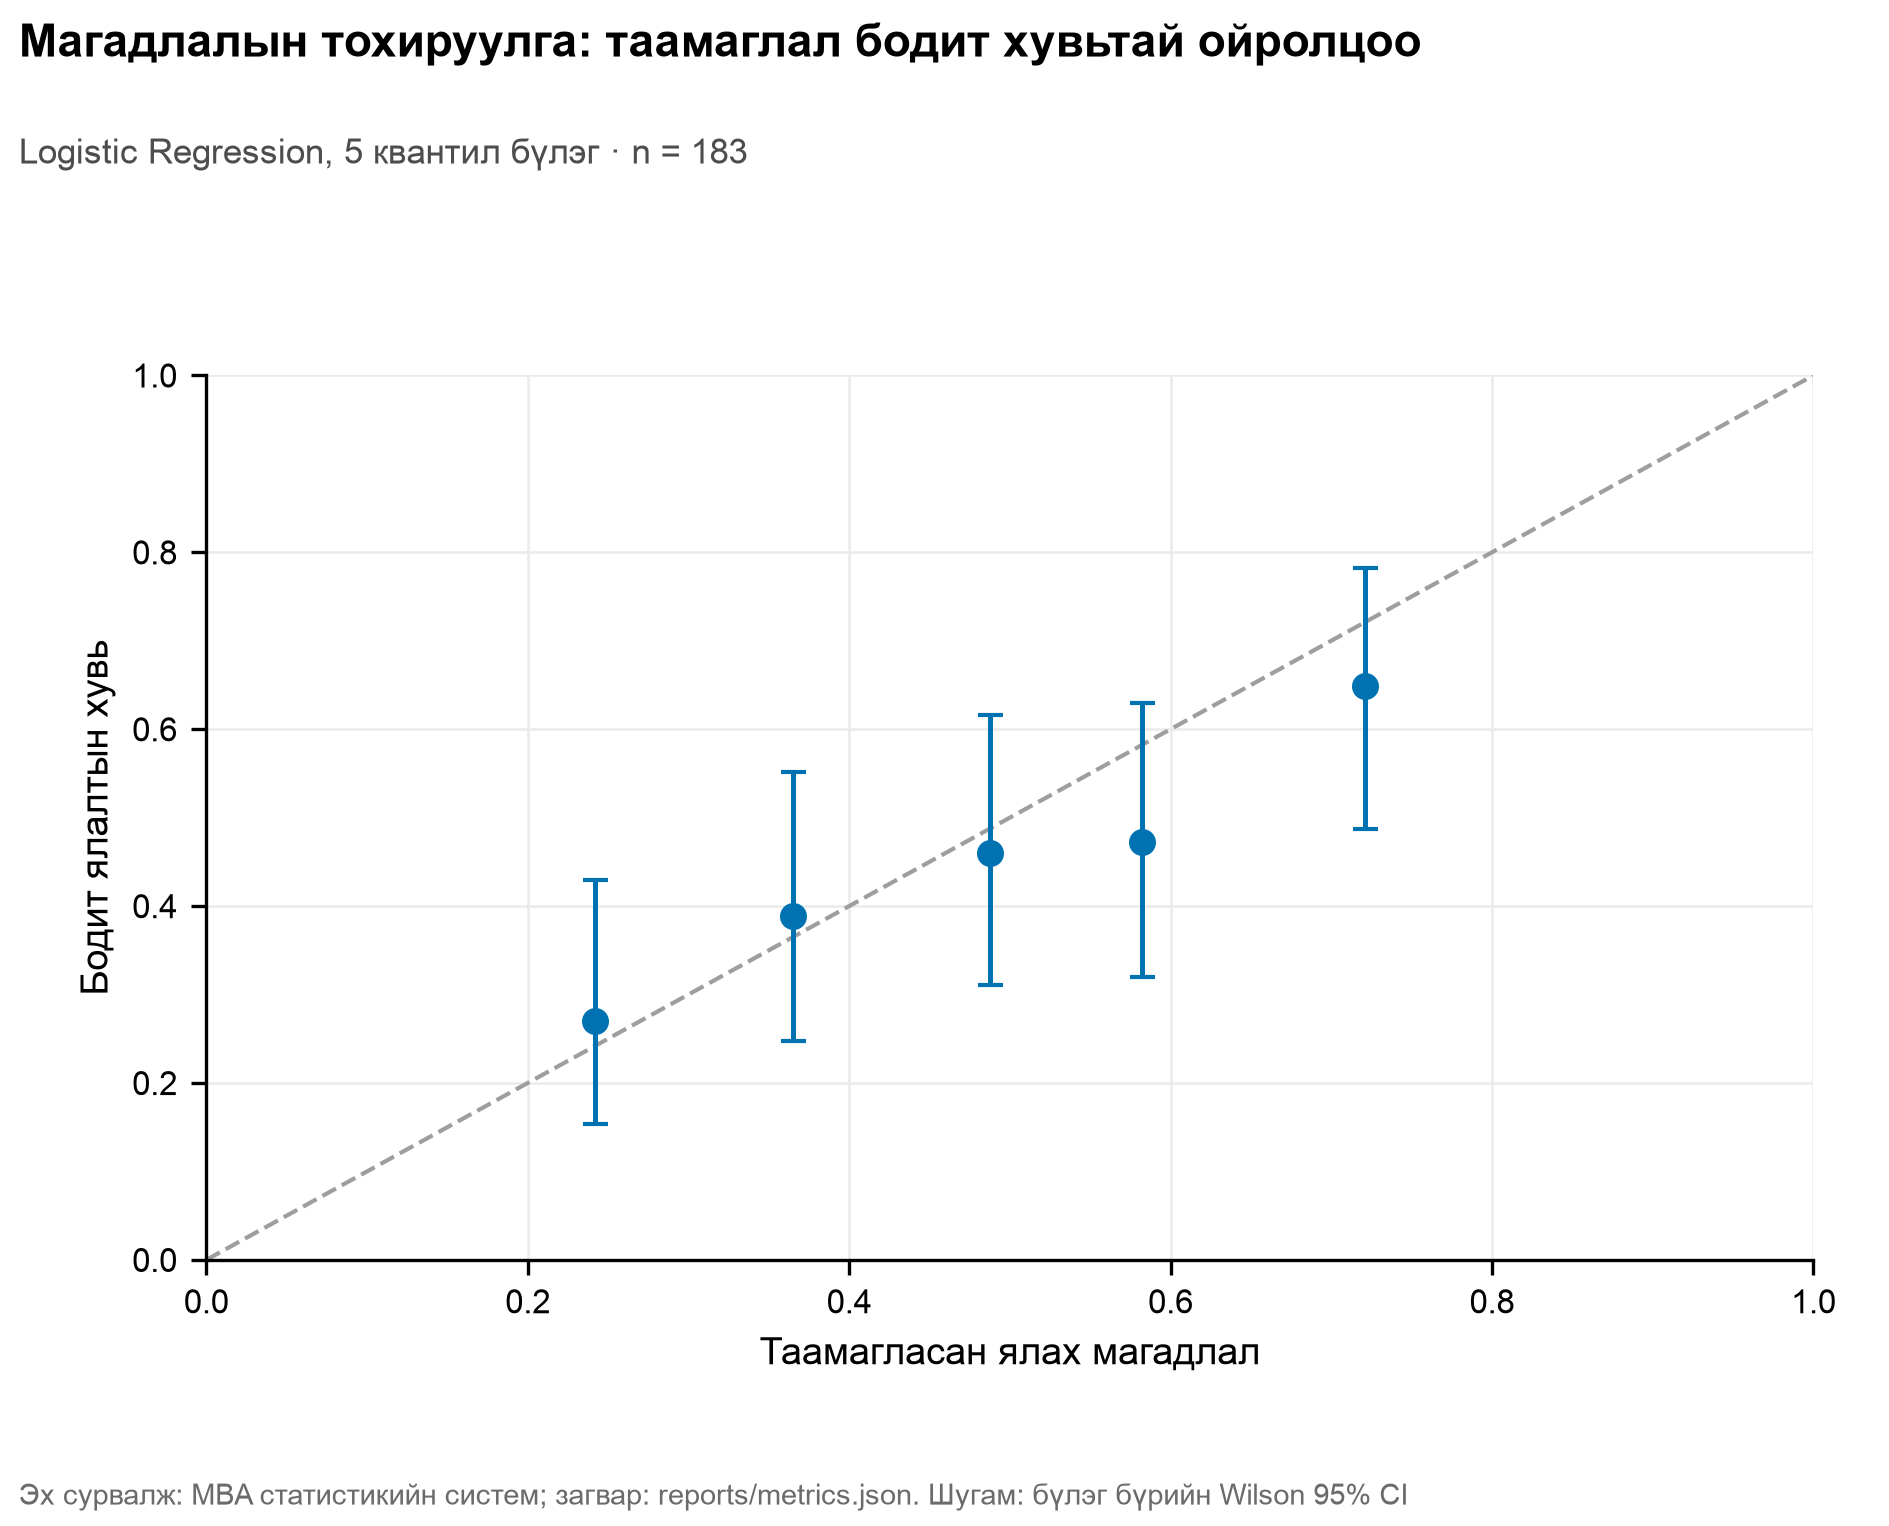

In [13]:
show("U06b_calibration")

**[Ноорог — өөрийн үгээр дахин бичих]** Загвар энгийн Elo baseline-ийг итгэх интервалын хэмжээнд давж чадаагүй — энэ нь өөрөө дүгнэлт: ~200 тоглолтын дата, баг хоорондын тэнцвэр.

## Тайлбар загвар ба Pythagorean

In [14]:
display(pd.read_csv(R / "explanatory.csv").round(3)); m["pythagorean"]

,feature,coef,lo,hi,perm_importance,perm_lo,perm_hi
0,efg,3.833,3.506,4.227,0.399,0.329,0.464
1,tov_pct,-1.914,-2.281,-1.589,0.093,0.064,0.116
2,orb_pct,1.574,1.249,1.953,0.073,0.056,0.095
3,ftr,1.010,0.679,1.431,0.034,0.020,0.047


{'exponent': 10.809989984867057,
 'exponent_ci': {'est': 10.809989984867057,
  'lo': 9.533777223711319,
  'hi': 12.10317673576825},
 'r2': 0.8861585148328418,
 'r2_ci': {'est': 0.8861585148328418,
  'lo': 0.7922641715417368,
  'hi': 0.9421569167640023},
 'mae': 0.05082439063695716,
 'mae_13_91': 0.06012112740153742,
 'n': 33}

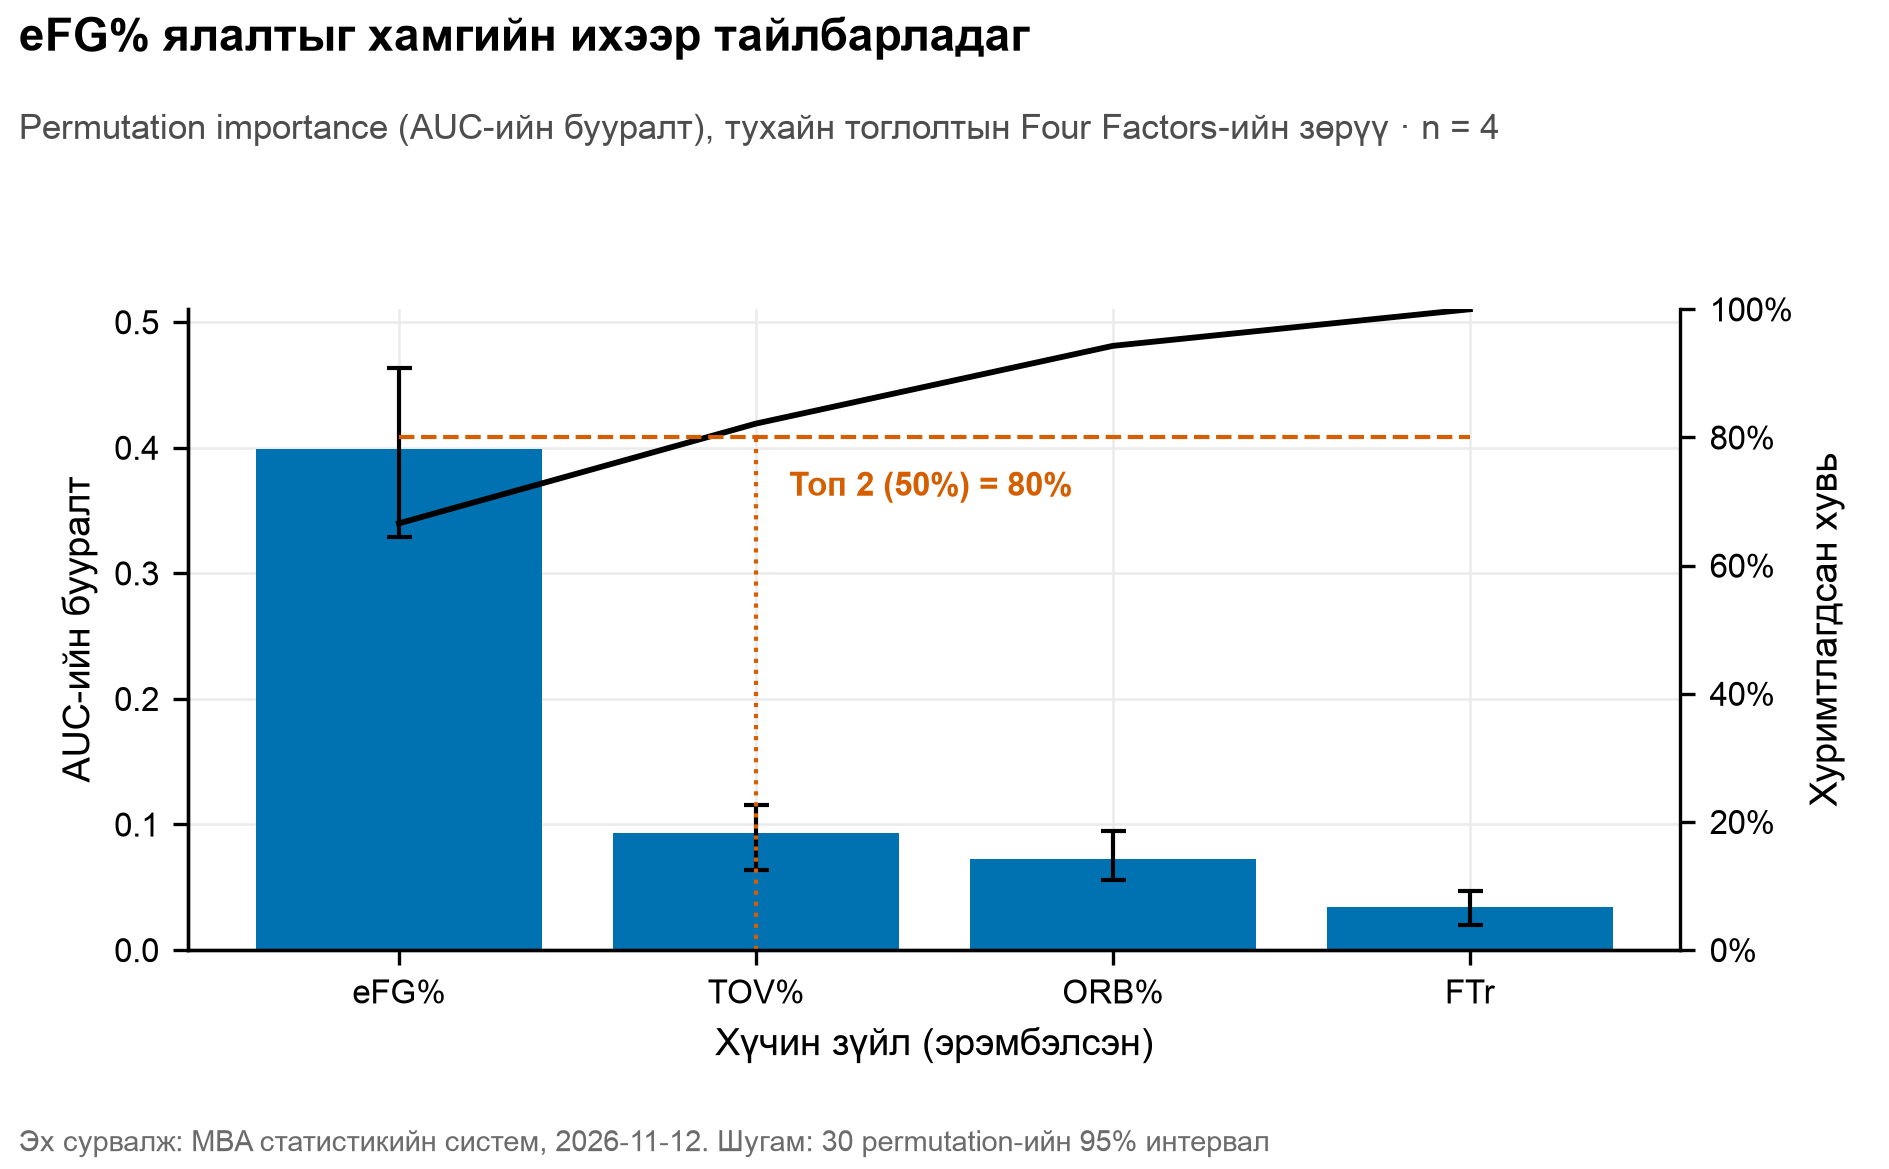

In [15]:
show("P3_importance_pareto")

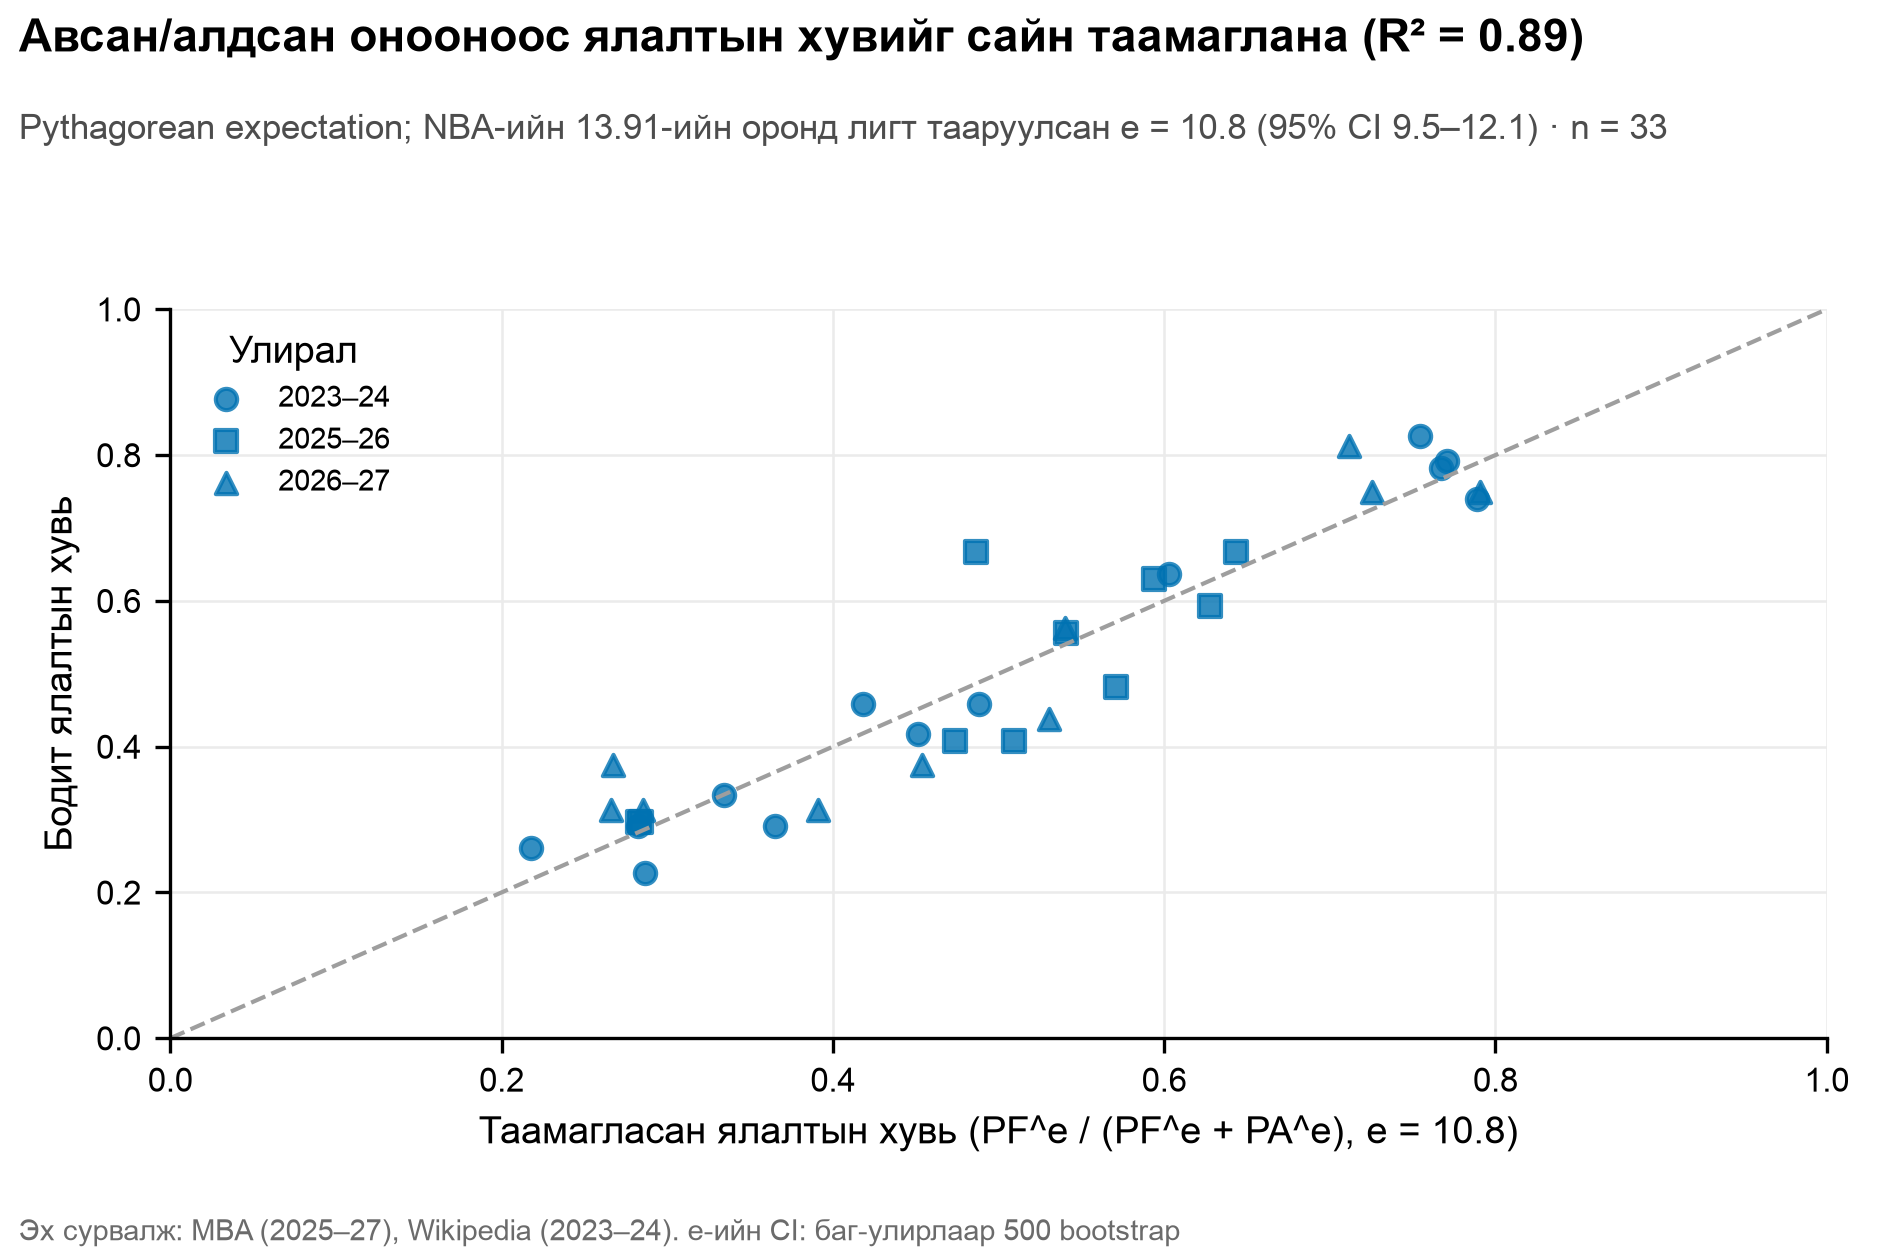

In [16]:
show("F13_pythagorean")